# Setup

In [1]:
from pathlib import Path
import sys, cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def find_project_root(max_up=6):
    p = Path.cwd()
    for _ in range(max_up+1):
        if (p/'src').exists() and (p/'configs').exists(): return p
        if p.parent==p: break
        p = p.parent
    return Path.cwd()

PROJECT_ROOT = find_project_root()
sys.path.append(str(PROJECT_ROOT))
from src.io_utils import save_csv
vis_dir = PROJECT_ROOT/'outputs'/'visualizations'/'evaluation'
vis_dir.mkdir(parents=True, exist_ok=True)
print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: D:\hoiancomputervision\ticket_suspicion_project


# Load outputs

In [2]:
tracks_df = pd.read_csv(PROJECT_ROOT/'outputs/tracks/tracks.csv')
tracklets_df = pd.read_csv(PROJECT_ROOT/'outputs/tracklets/tracklets_summary.csv')
rep_df = pd.read_csv(PROJECT_ROOT/'outputs/crops/representative_crops.csv')
global_df = pd.read_csv(PROJECT_ROOT/'outputs/global_ids/global_ids.csv')
events_df = pd.read_csv(PROJECT_ROOT/'outputs/events/events.csv')
journey_df = pd.read_csv(PROJECT_ROOT/'outputs/journeys/journey_states.csv')
alerts_df = pd.read_csv(PROJECT_ROOT/'outputs/alerts/alerts.csv')
print('Loaded all outputs.')

Loaded all outputs.


# Evaluation summary (aggregate)

In [3]:
seq_col = 'sequence_name' if 'sequence_name' in tracks_df.columns else 'camera_id'
result_summary = {
    'num_sequences': int(tracks_df[seq_col].nunique()),
    'num_frames_processed': int(tracks_df['frame_id'].nunique()),
    'num_tracking_rows': int(len(tracks_df)),
    'num_local_tracks': int(tracks_df['local_track_id'].nunique()),
    'num_total_tracklets': int(len(tracklets_df)),
    'num_valid_tracklets': int(tracklets_df['valid'].sum()),
    'num_global_ids': int(len(global_df)),
    'num_ticket_evidence': int(global_df['ticket_evidence'].sum()),
    'num_events': int(len(events_df)),
    'num_journey_suspected': int((journey_df['journey_state']=='suspected_no_ticket_evidence').sum()),
    'num_alert_generated': int((alerts_df['status']=='alert_generated').sum()),
    'num_watchlist': int((alerts_df['status']=='watchlist').sum()),
    'num_no_alert': int((alerts_df['status']=='no_alert').sum())
}
summary_df = pd.DataFrame([{'metric':k,'value':v} for k,v in result_summary.items()])
save_csv(summary_df, PROJECT_ROOT/'outputs/evaluation_summary.csv')
summary_df

,metric,value
0,num_sequences,7
1,num_frames_processed,1050
2,num_tracking_rows,45445
3,num_local_tracks,700
4,num_total_tracklets,704
5,num_valid_tracklets,364
6,num_global_ids,364
7,num_ticket_evidence,219
8,num_events,583
9,num_journey_suspected,8


# Per-Sequence Breakdown

In [4]:
per_seq_rows = []
for seq_name, st in tracks_df.groupby(seq_col):
    n_frames=st['frame_id'].nunique(); n_det=len(st); n_tracks=st['local_track_id'].nunique()
    avg_conf=st['confidence'].mean() if 'confidence' in st.columns else 0
    cam_id=seq_name
    stl=tracklets_df[tracklets_df['camera_id']==cam_id] if 'camera_id' in tracklets_df.columns else pd.DataFrame()
    n_tl=len(stl); n_tv=int(stl['valid'].sum()) if len(stl)>0 and 'valid' in stl.columns else 0
    per_seq_rows.append({'sequence':seq_name,'frames':n_frames,'detections':n_det,'tracks':n_tracks,
        'avg_det_per_frame':round(n_det/n_frames,1),'avg_confidence':round(avg_conf,3),
        'tracklets_total':n_tl,'tracklets_valid':n_tv,'valid_ratio':round(n_tv/n_tl,3) if n_tl>0 else 0})
per_seq_df = pd.DataFrame(per_seq_rows)
save_csv(per_seq_df, PROJECT_ROOT/'outputs/per_sequence_summary.csv')
per_seq_df

,sequence,frames,detections,tracks,avg_det_per_frame,avg_confidence,tracklets_total,tracklets_valid,valid_ratio
0,MOT17-02-FRCNN,600,4338,77,7.2,0.665,77,43,0.558
1,MOT17-04-FRCNN,1049,18022,116,17.2,0.635,116,78,0.672
2,MOT17-05-FRCNN,836,4560,151,5.5,0.779,151,74,0.490
3,MOT17-09-FRCNN,524,4112,57,7.8,0.711,57,34,0.596
4,MOT17-10-FRCNN,654,5291,112,8.1,0.665,112,44,0.393
5,MOT17-11-FRCNN,900,6220,92,6.9,0.795,92,48,0.522
6,MOT17-13-FRCNN,730,2902,99,4.0,0.624,99,43,0.434


# Per-Sequence Bar Charts

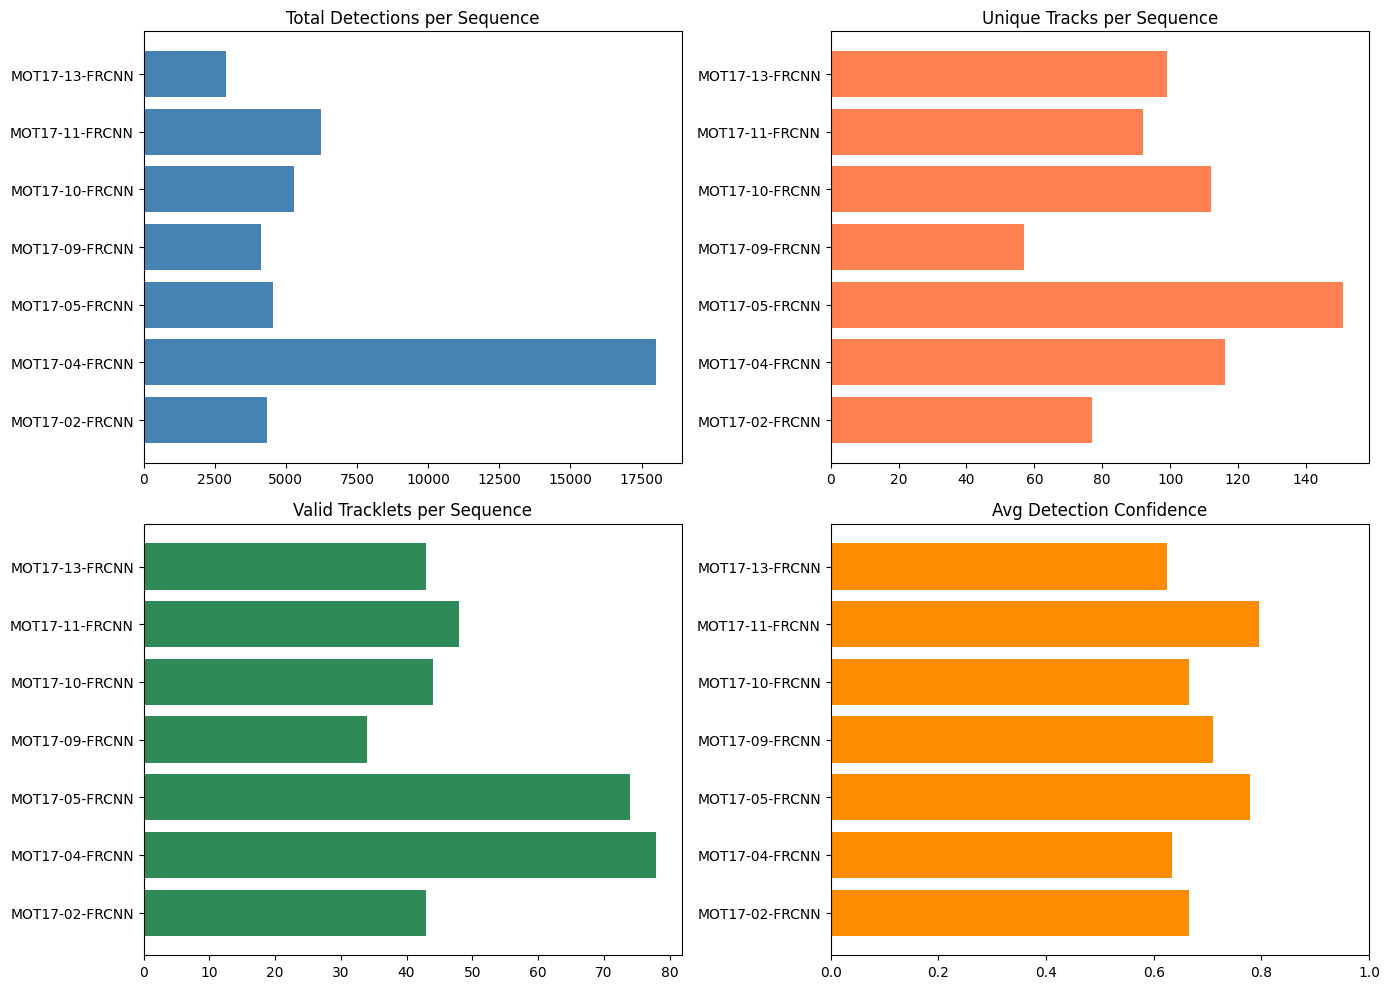

In [5]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
axes[0,0].barh(per_seq_df['sequence'],per_seq_df['detections'],color='steelblue')
axes[0,0].set_title('Total Detections per Sequence')
axes[0,1].barh(per_seq_df['sequence'],per_seq_df['tracks'],color='coral')
axes[0,1].set_title('Unique Tracks per Sequence')
axes[1,0].barh(per_seq_df['sequence'],per_seq_df['tracklets_valid'],color='seagreen')
axes[1,0].set_title('Valid Tracklets per Sequence')
axes[1,1].barh(per_seq_df['sequence'],per_seq_df['avg_confidence'],color='darkorange')
axes[1,1].set_title('Avg Detection Confidence'); axes[1,1].set_xlim(0,1)
plt.tight_layout(); plt.savefig(vis_dir/'per_sequence_comparison.png',dpi=150); plt.show()

# Qualitative Analysis — Tracking Visualization per Scene (Proposal #3)

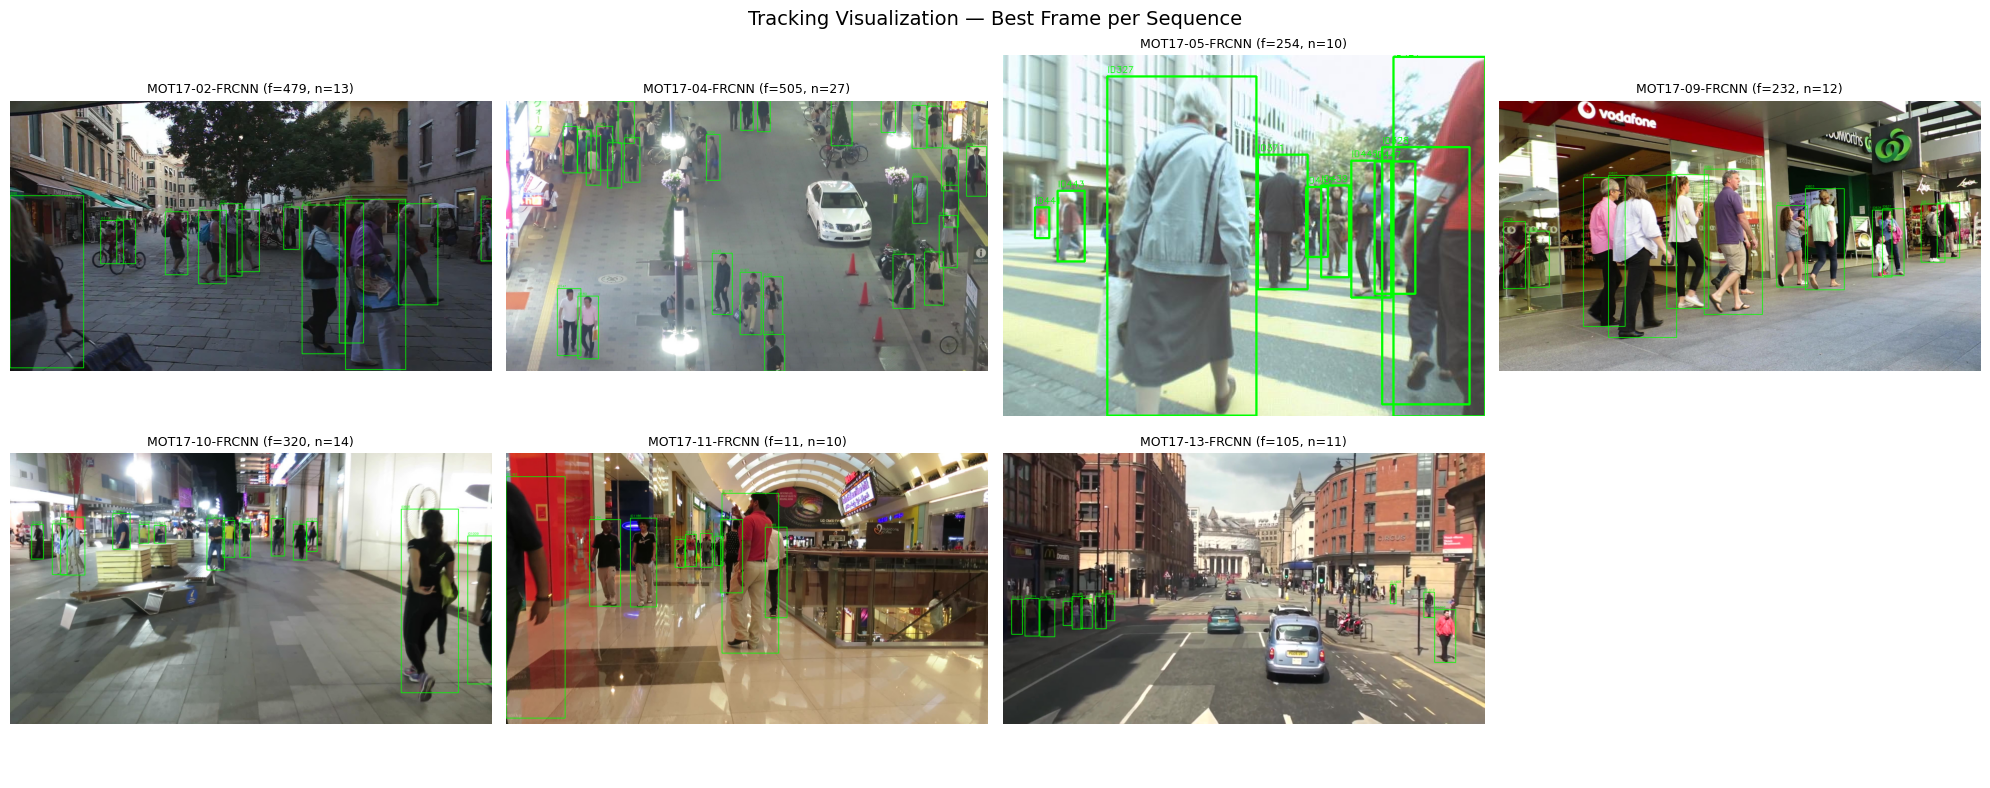

Saved: qualitative_tracking_per_scene.png


In [6]:
# Hiển thị 1 frame mẫu per sequence với bbox + track ID
sequences = tracks_df[seq_col].unique()
n_seq = len(sequences)
cols = min(4, n_seq)
rows_grid = (n_seq + cols - 1) // cols

fig, axes = plt.subplots(rows_grid, cols, figsize=(5*cols, 4*rows_grid))
if rows_grid == 1: axes = [axes] if cols == 1 else [axes]
if cols == 1: axes = [[ax] for ax in axes]

for idx, seq_name in enumerate(sorted(sequences)):
    r, c = idx // cols, idx % cols
    ax = axes[r][c] if rows_grid > 1 else axes[0][c]
    
    seq_tracks = tracks_df[tracks_df[seq_col] == seq_name]
    # Chọn frame có nhiều người nhất
    frame_counts = seq_tracks.groupby('frame_id').size()
    best_frame = frame_counts.idxmax()
    frame_data = seq_tracks[seq_tracks['frame_id'] == best_frame]
    
    img_path = frame_data.iloc[0]['image_path']
    img = cv2.imread(img_path)
    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        for _, det in frame_data.iterrows():
            x1,y1,x2,y2 = int(det['x1']),int(det['y1']),int(det['x2']),int(det['y2'])
            cv2.rectangle(img_rgb,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(img_rgb,f"ID{int(det['local_track_id'])}",(x1,max(0,y1-5)),cv2.FONT_HERSHEY_SIMPLEX,0.4,(0,255,0),1)
        ax.imshow(img_rgb)
    ax.set_title(f'{seq_name} (f={best_frame}, n={len(frame_data)})', fontsize=9)
    ax.axis('off')

# Hide unused axes
for idx in range(n_seq, rows_grid*cols):
    r, c = idx // cols, idx % cols
    ax = axes[r][c] if rows_grid > 1 else axes[0][c]
    ax.axis('off')

plt.suptitle('Tracking Visualization — Best Frame per Sequence', fontsize=14)
plt.tight_layout()
plt.savefig(vis_dir/'qualitative_tracking_per_scene.png', dpi=150)
plt.show()
print('Saved: qualitative_tracking_per_scene.png')

# Qualitative Analysis — Crop Quality Showcase

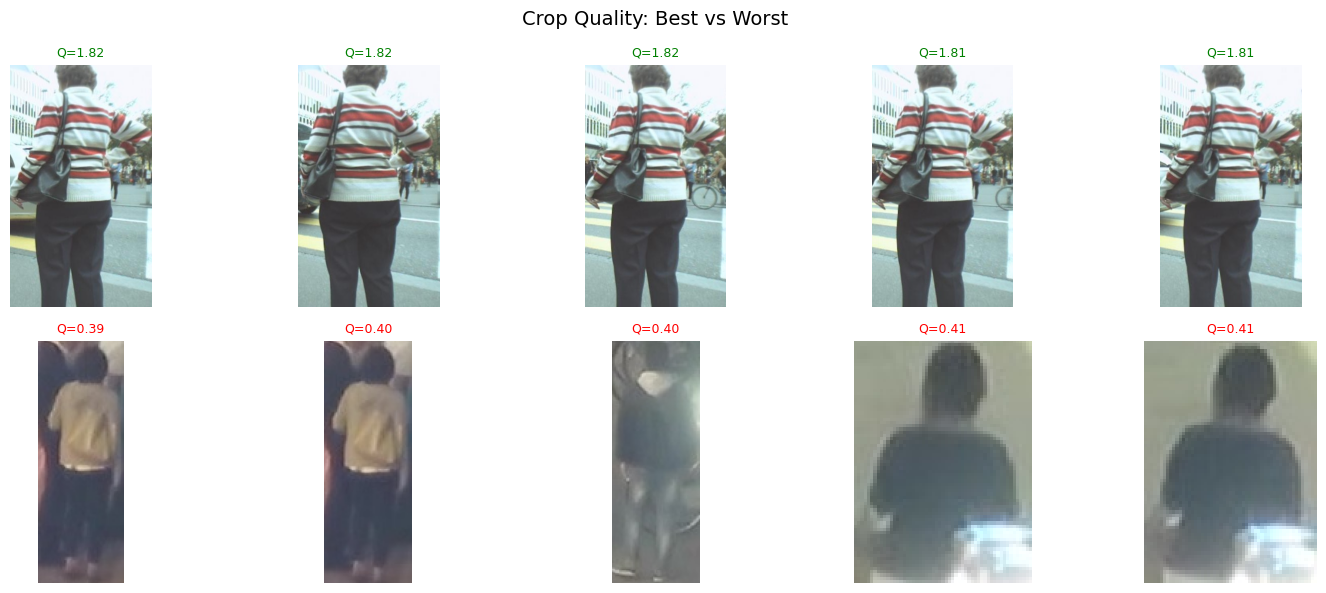

In [7]:
# Top 5 crop tốt nhất vs 5 xấu nhất
if 'quality_score' in rep_df.columns and 'crop_path' in rep_df.columns:
    top5 = rep_df.nlargest(5, 'quality_score')
    bot5 = rep_df.nsmallest(5, 'quality_score')
    
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for i, (_, row) in enumerate(top5.iterrows()):
        img = cv2.imread(row['crop_path'])
        if img is not None:
            axes[0,i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[0,i].set_title(f"Q={row['quality_score']:.2f}", fontsize=9, color='green')
        axes[0,i].axis('off')
    
    for i, (_, row) in enumerate(bot5.iterrows()):
        img = cv2.imread(row['crop_path'])
        if img is not None:
            axes[1,i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[1,i].set_title(f"Q={row['quality_score']:.2f}", fontsize=9, color='red')
        axes[1,i].axis('off')
    
    axes[0,0].set_ylabel('Best', fontsize=12, rotation=0, labelpad=40)
    axes[1,0].set_ylabel('Worst', fontsize=12, rotation=0, labelpad=40)
    plt.suptitle('Crop Quality: Best vs Worst', fontsize=14)
    plt.tight_layout()
    plt.savefig(vis_dir/'qualitative_crop_quality.png', dpi=150)
    plt.show()
else:
    print('quality_score or crop_path column not found in representative_crops.csv')

# Qualitative Analysis — Alert Examples

In [8]:
# Top 3 high alerts vs 3 no-alerts
high_ex = alerts_df[alerts_df['status']=='alert_generated'].nlargest(3,'suspicion_score') if 'suspicion_score' in alerts_df.columns else pd.DataFrame()
low_ex = alerts_df[alerts_df['status']=='no_alert'].nsmallest(3,'suspicion_score') if 'suspicion_score' in alerts_df.columns else pd.DataFrame()

print('=== TOP HIGH ALERTS (alert_generated) ===')
for _, row in high_ex.iterrows():
    print(f"  {row['global_id']}: score={row['suspicion_score']:.3f}, ticket={row.get('ticket_evidence','?')}, reason={row.get('reason','?')}")

print('\n=== TOP LOW ALERTS (no_alert) ===')
for _, row in low_ex.iterrows():
    print(f"  {row['global_id']}: score={row['suspicion_score']:.3f}, ticket={row.get('ticket_evidence','?')}, reason={row.get('reason','?')}")

=== TOP HIGH ALERTS (alert_generated) ===
  GID_00001: score=0.960, ticket=False, reason=Entered area detected; No ticket counter evidence; Exceeded maximum travel time
  GID_00002: score=0.960, ticket=False, reason=Entered area detected; No ticket counter evidence; Exceeded maximum travel time
  GID_00007: score=0.960, ticket=False, reason=Entered area detected; No ticket counter evidence; Exceeded maximum travel time

=== TOP LOW ALERTS (no_alert) ===
  GID_00339: score=0.432, ticket=True, reason=Entered area detected
  GID_00023: score=0.433, ticket=True, reason=Entered area detected
  GID_00056: score=0.434, ticket=True, reason=Entered area detected


# Alert & Score Distributions

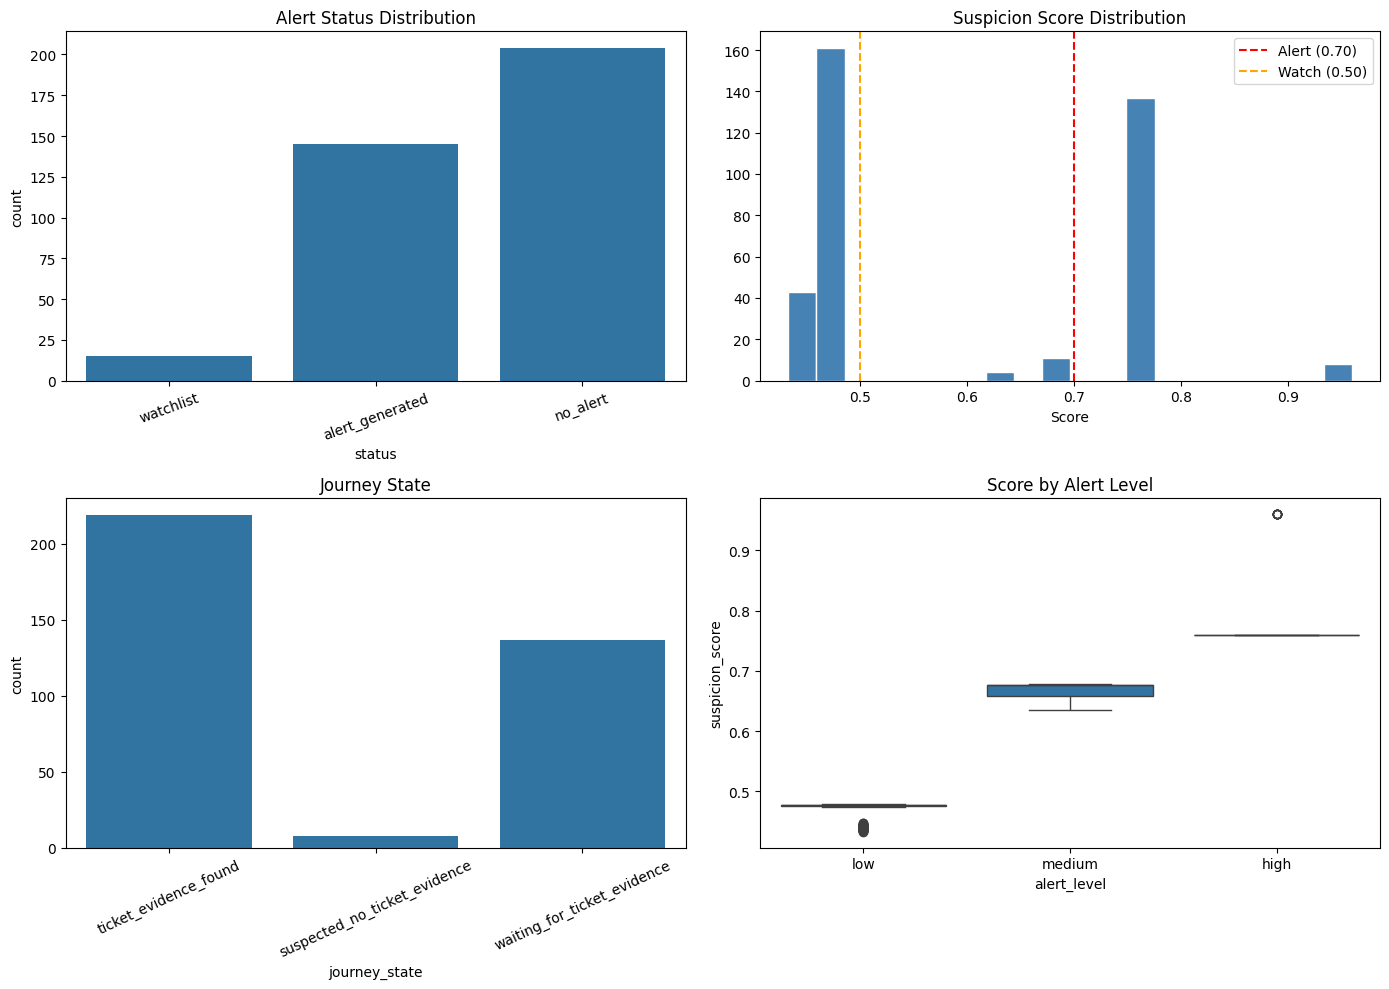

In [9]:
fig, axes = plt.subplots(2,2,figsize=(14,10))

# Alert status
sns.countplot(data=alerts_df, x='status', ax=axes[0,0])
axes[0,0].set_title('Alert Status Distribution'); axes[0,0].tick_params(axis='x',rotation=20)

# Score histogram + thresholds
axes[0,1].hist(alerts_df['suspicion_score'],bins=20,color='steelblue',edgecolor='white')
axes[0,1].axvline(x=0.70,color='red',linestyle='--',label='Alert (0.70)')
axes[0,1].axvline(x=0.50,color='orange',linestyle='--',label='Watch (0.50)')
axes[0,1].set_xlabel('Score'); axes[0,1].set_title('Suspicion Score Distribution'); axes[0,1].legend()

# Journey state
sns.countplot(data=journey_df, x='journey_state', ax=axes[1,0])
axes[1,0].set_title('Journey State'); axes[1,0].tick_params(axis='x',rotation=25)

# Boxplot by alert level
if 'alert_level' in alerts_df.columns:
    order=[l for l in ['low','medium','high'] if l in alerts_df['alert_level'].values]
    sns.boxplot(data=alerts_df, x='alert_level', y='suspicion_score', order=order, ax=axes[1,1])
    axes[1,1].set_title('Score by Alert Level')

plt.tight_layout(); plt.savefig(vis_dir/'alert_score_distributions.png',dpi=150); plt.show()

# Scoring Sensitivity Analysis

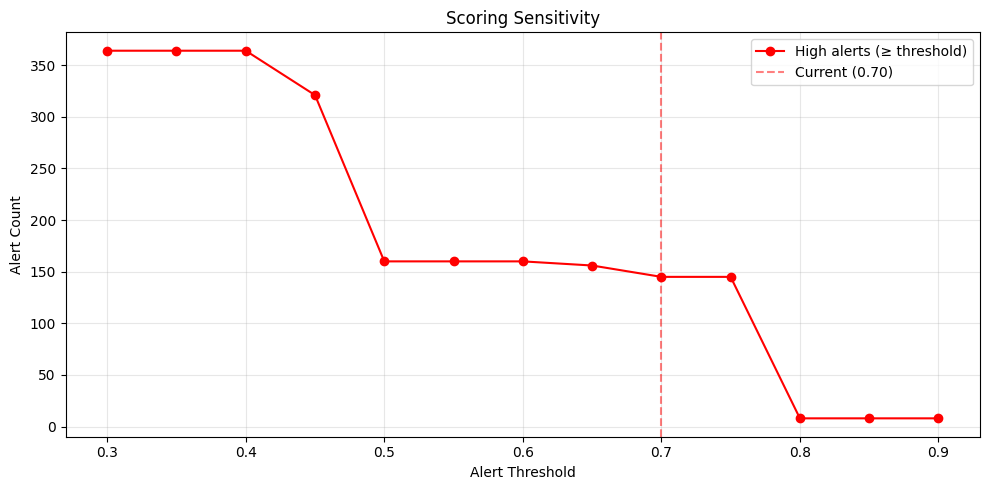

,threshold,high_alerts,ratio
0,0.30,364,1.000000
1,0.35,364,1.000000
2,0.40,364,1.000000
3,0.45,321,0.881868
4,0.50,160,0.439560
5,0.55,160,0.439560
6,0.60,160,0.439560
7,0.65,156,0.428571
8,0.70,145,0.398352
9,0.75,145,0.398352


In [10]:
thresholds=np.arange(0.3,0.95,0.05)
high_counts=[(alerts_df['suspicion_score']>=t).sum() for t in thresholds]

fig,ax=plt.subplots(figsize=(10,5))
ax.plot(thresholds,high_counts,'o-',color='red',label='High alerts (≥ threshold)')
ax.axvline(x=0.70,color='red',linestyle='--',alpha=0.5,label='Current (0.70)')
ax.set_xlabel('Alert Threshold'); ax.set_ylabel('Alert Count')
ax.set_title('Scoring Sensitivity'); ax.legend(); ax.grid(True,alpha=0.3)
plt.tight_layout(); plt.savefig(vis_dir/'scoring_sensitivity.png',dpi=150); plt.show()

sens_df=pd.DataFrame({'threshold':thresholds,'high_alerts':high_counts,'ratio':[c/len(alerts_df) for c in high_counts]})
save_csv(sens_df,PROJECT_ROOT/'outputs/alerts/scoring_sensitivity.csv')
sens_df

# Failure Case Analysis (Proposal #6)

In [11]:
# A) Tracking fragmentation: tracklets quá ngắn = tracking bị phân mảnh
if 'num_frames' in tracklets_df.columns:
    short = tracklets_df[tracklets_df['num_frames'] < 5]
    total = len(tracklets_df)
    print(f'Short tracklets (< 5 frames): {len(short)}/{total} ({len(short)/total:.1%})')
    
    if 'camera_id' in tracklets_df.columns:
        print('\nPer-sequence fragmentation:')
        for cam_id, g in tracklets_df.groupby('camera_id'):
            s = (g['num_frames'] < 5).sum()
            print(f'  {cam_id}: {s}/{len(g)} short ({s/len(g):.1%})')

# B) Alert failures (trên simulation)
if 'ticket_evidence' in alerts_df.columns and 'status' in alerts_df.columns:
    # False alerts: có vé nhưng vẫn bị alert
    false_alerts = alerts_df[(alerts_df['ticket_evidence']==True) & (alerts_df['status']=='alert_generated')]
    # Missed: không có vé nhưng không bị alert
    missed = alerts_df[(alerts_df['ticket_evidence']==False) & (alerts_df['status']=='no_alert')]
    
    print(f'\n=== ALERT FAILURE ANALYSIS ===')
    print(f'False Alerts (có vé nhưng bị alert): {len(false_alerts)}')
    print(f'Missed (không vé nhưng no_alert):    {len(missed)}')
    
    total_positive = (alerts_df['ticket_evidence']==False).sum()  # should be alerted
    total_negative = (alerts_df['ticket_evidence']==True).sum()   # should NOT be alerted
    
    if total_positive > 0:
        detected = ((alerts_df['ticket_evidence']==False) & (alerts_df['status']=='alert_generated')).sum()
        print(f'\nDetection rate (no-ticket → alert): {detected}/{total_positive} ({detected/total_positive:.1%})')
    if total_negative > 0:
        false_alarm = len(false_alerts)
        print(f'False alarm rate (has-ticket → alert): {false_alarm}/{total_negative} ({false_alarm/total_negative:.1%})')

Short tracklets (< 5 frames): 171/704 (24.3%)

Per-sequence fragmentation:
  MOT17-02-FRCNN: 17/77 short (22.1%)
  MOT17-04-FRCNN: 17/116 short (14.7%)
  MOT17-05-FRCNN: 39/151 short (25.8%)
  MOT17-09-FRCNN: 12/57 short (21.1%)
  MOT17-10-FRCNN: 32/112 short (28.6%)
  MOT17-11-FRCNN: 17/92 short (18.5%)
  MOT17-13-FRCNN: 37/99 short (37.4%)

=== ALERT FAILURE ANALYSIS ===
False Alerts (có vé nhưng bị alert): 0
Missed (không vé nhưng no_alert):    0

Detection rate (no-ticket → alert): 145/145 (100.0%)
False alarm rate (has-ticket → alert): 0/219 (0.0%)


In [12]:
# C) Detection density analysis — cảnh nào khó nhất?
print('\n=== DETECTION DENSITY ANALYSIS ===')
for seq_name, st in tracks_df.groupby(seq_col):
    n_frames = st['frame_id'].nunique()
    avg_det = len(st) / n_frames if n_frames > 0 else 0
    max_det = st.groupby('frame_id').size().max()
    print(f'  {seq_name}: avg={avg_det:.1f} det/frame, max={max_det} det/frame, total_frames={n_frames}')


=== DETECTION DENSITY ANALYSIS ===
  MOT17-02-FRCNN: avg=7.2 det/frame, max=13 det/frame, total_frames=600
  MOT17-04-FRCNN: avg=17.2 det/frame, max=27 det/frame, total_frames=1049
  MOT17-05-FRCNN: avg=5.5 det/frame, max=10 det/frame, total_frames=836
  MOT17-09-FRCNN: avg=7.8 det/frame, max=12 det/frame, total_frames=524
  MOT17-10-FRCNN: avg=8.1 det/frame, max=14 det/frame, total_frames=654
  MOT17-11-FRCNN: avg=6.9 det/frame, max=10 det/frame, total_frames=900
  MOT17-13-FRCNN: avg=4.0 det/frame, max=11 det/frame, total_frames=730


# Export thesis tables

In [13]:
thesis_alert_table = alerts_df[['global_id','ticket_evidence','journey_state','suspicion_score','alert_level','status','reason']].copy()
save_csv(thesis_alert_table, PROJECT_ROOT/'outputs/alerts/thesis_alert_table.csv')
print('Saved thesis tables.')
thesis_alert_table.head()

Saved thesis tables.


,global_id,ticket_evidence,journey_state,suspicion_score,alert_level,status,reason
0,GID_00000,True,ticket_evidence_found,0.677053,medium,watchlist,Entered area detected; Exceeded maximum travel...
1,GID_00001,False,suspected_no_ticket_evidence,0.960000,high,alert_generated,Entered area detected; No ticket counter evide...
2,GID_00002,False,suspected_no_ticket_evidence,0.960000,high,alert_generated,Entered area detected; No ticket counter evide...
3,GID_00003,True,ticket_evidence_found,0.677599,medium,watchlist,Entered area detected; Exceeded maximum travel...
4,GID_00004,True,ticket_evidence_found,0.642776,medium,watchlist,Entered area detected; Exceeded maximum travel...


# Pipeline flow health check

In [14]:
def count_files(root,pats):
    t=0
    for p in pats: t+=len(list(root.rglob(p)))
    return t
outputs_dir=PROJECT_ROOT/'outputs'
checks={'frame_index':count_files(outputs_dir,['*frame_index*.csv']),'tracks':count_files(outputs_dir,['*track*.csv']),'crops':count_files(outputs_dir,['*.jpg','*.png']),'embeddings':count_files(outputs_dir,['*embedding*.csv','*embedding*.npy','*embeddings*.csv','*embeddings*.npy']),'scores':count_files(outputs_dir,['*score*.csv','*event*.csv']),'evidence':count_files(outputs_dir,['*evidence*.csv','*evidence*.json','*.mp4'])}
print('FLOW HEALTH CHECK'); print('='*40)
all_ok=True
for k,v in checks.items():
    s='OK' if v>0 else 'MISSING'; print(f'{k:20s}: {s:8s} ({v})')
    if v==0: all_ok=False
print('='*40); print('OVERALL:','PASS' if all_ok else 'CHECK REQUIRED')

FLOW HEALTH CHECK
frame_index         : OK       (1)
tracks              : OK       (3)
crops               : OK       (2270)
embeddings          : OK       (8)
scores              : OK       (1)
evidence            : OK       (1)
OVERALL: PASS
